<a href="https://colab.research.google.com/github/slimani-meriem/unet-oxford-pets/blob/main/01_CamVid_data_exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import os
from google.colab import userdata

token = userdata.get('GITHUB_TOKEN')
repo_dir = '/content/unet-oxford-pets'

if not os.path.exists(repo_dir):
    !git clone -q https://{token}@github.com/slimani-meriem/unet-oxford-pets.git {repo_dir}
else:
    !git -C {repo_dir} pull

%cd {repo_dir}

remote: Enumerating objects: 7, done.
remote: Counting objects: 100% (7/7), done.
remote: Compressing objects: 100% (1/1), done.
remote: Total 4 (delta 3), reused 4 (delta 3), pack-reused 0 (from 0)
Unpacking objects: 100% (4/4), 366 bytes | 52.00 KiB/s, done.
From https://github.com/slimani-meriem/unet-oxford-pets
   120e0ef..107ece4  main       -> origin/main
Updating 120e0ef..107ece4
Fast-forward
 src/dataset.py | 2 +-
 1 file changed, 1 insertion(+), 1 deletion(-)
/content/unet-oxford-pets


In [3]:
!pip install -q -e .

  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for camvid-segmentation (pyproject.toml) ... done


In [ ]:
!ls
import torch
print(torch.cuda.is_available(), torch.cuda.get_device_name(0))

LICENSE  notebooks  README.md  requirements.txt  src
True Tesla T4


## Importing the CamVid dataset from Kaggle
Link to the dataset : https://www.kaggle.com/datasets/carlolepelaars/camvid

It is already split into train, test and validation images and labels.

In [4]:
!pip install -q --upgrade kaggle

import os
from getpass import getpass

token = getpass("Kaggle token : ")
os.makedirs(os.path.expanduser("~/.kaggle"), exist_ok=True)
path = os.path.expanduser("~/.kaggle/access_token")
with open(path, "w") as f:
    f.write(token)
os.chmod(path, 0o600)

Kaggle token : ··········


In [5]:
!kaggle datasets download -d carlolepelaars/camvid
!unzip -q camvid.zip -d data/

Dataset URL: https://www.kaggle.com/datasets/carlolepelaars/camvid
License(s): CC-BY-NC-SA-4.0
camvid.zip: Skipping, found more recently modified local copy (use --force to force download)
replace data/CamVid/class_dict.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: 

## Explore the imported dataset
We are going to take a random image as an example (let's say the first image of the training set), and visualize its label, which in this case is the correponding mask with the apporopriate classes.

There are 4 different pixel's values : [0, 64, 128, 192].

To be able to identify the class of a pixel, we need to see the values it takes in the three different channels.

Check the class-to-color mapping in : https://www.cril.univ-artois.fr/pyimagelabeling/datasets/camvid

In [ ]:
import os

for root, dirs, files in os.walk("data"):
    depth = root.count(os.sep)
    if depth <= 2:
        print(f"{root}  ->  {len(files)} file(s), {len(dirs)} subfolder(s)")

data  ->  0 file(s), 1 subfolder(s)
data/CamVid  ->  1 file(s), 6 subfolder(s)
data/CamVid/test  ->  232 file(s), 0 subfolder(s)
data/CamVid/test_labels  ->  232 file(s), 0 subfolder(s)
data/CamVid/val_labels  ->  100 file(s), 0 subfolder(s)
data/CamVid/train_labels  ->  369 file(s), 0 subfolder(s)
data/CamVid/val  ->  100 file(s), 0 subfolder(s)
data/CamVid/train  ->  369 file(s), 0 subfolder(s)


image: (960, 720) RGB
mask: (960, 720) RGB
mask values: [  0  64 128 192]
(720, 960, 3)
nb colours : 15
colours (for each channel of a pixel): 
 [[  0   0   0]
 [  0   0 192]
 [  0  64  64]
 [  0 128 192]
 [ 64   0 128]
 [ 64  64   0]
 [ 64 128 192]
 [ 64 192   0]
 [128   0   0]
 [128   0 192]
 [128  64 128]
 [128 128   0]
 [128 128  64]
 [128 128 128]
 [192 192 128]]


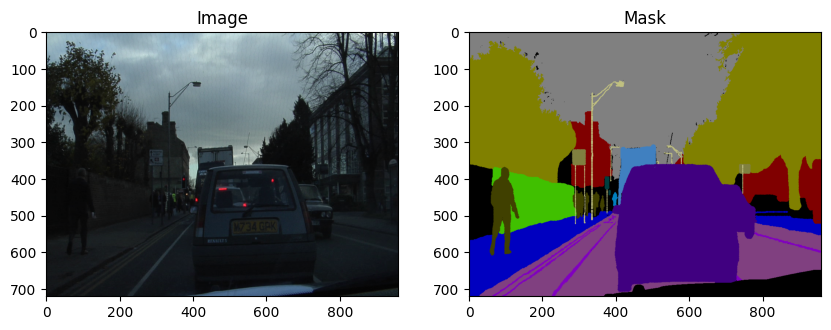

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

img_path = "data/CamVid/train/0001TP_009210.png"
mask_path = "data/CamVid/train_labels/0001TP_009210_L.png"

img = Image.open(img_path)
mask = Image.open(mask_path)

print("image:", img.size, img.mode)
print("mask:", mask.size, mask.mode)
print("mask values:", np.unique(np.array(mask)))

mask_rgb = np.array(mask.convert("RGB"))
print(mask_rgb.shape)
unique_colors = np.unique(
    mask_rgb.reshape(-1, 3),
    axis=0
)

print("nb colours :", len(unique_colors))
print("colours (for each channel of a pixel): \n", unique_colors)

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].imshow(img)
ax[0].set_title("Image")
ax[1].imshow(mask)
ax[1].set_title("Mask")
plt.show()

## Checking the images sizes
With the cell below, we can conclude that all the images of the dataset (across different splits) have the smae size (960, 720).

Different image sizes would have required a preprocessing before feeding them to the U-net.

In [ ]:
import os
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

DATA_DIR = "data/CamVid"

SPLITS = {
    "train" : ("train", "train_labels"),
    "val" : ("val", "val_labels"),
    "test" : ("test", "test_labels")
}

def list_files(folder):
  return sorted(f for f in os.listdir(folder) if f.lower().endswith((".png", ".jpg", ".jpeg")))

def get_size(path):
  with Image.open(path) as im :
    return im.size

for split, (img_folder, mask_folder) in SPLITS.items():
  img_dir = os.path.join(DATA_DIR, img_folder)
  mask_dir = os.path.join(DATA_DIR, mask_folder)
  img_files, mask_files = list_files(img_dir), list_files(mask_dir)

  img_sizes = Counter(get_size(os.path.join(img_dir, f)) for f in img_files)
  mask_sizes = Counter(get_size(os.path.join(mask_dir, f)) for f in mask_files)

  # Little security check : checking if each image has the same size as its mask (we assume sorted names line up)
  mismatched = sum(
      get_size(os.path.join(img_dir, fi)) != get_size(os.path.join(mask_dir, fm))
      for fi, fm in zip(img_files, mask_files)
  )


  print(f"=== {split} ===")
  print(f"images: {len(img_files)} | masks: {len(mask_files)}")
  print("image sizes:", dict(img_sizes))
  print("mask sizes: ", dict(mask_sizes))
  print("image/mask size mismatches:", mismatched)

=== train ===
images: 369 | masks: 369
image sizes: {(960, 720): 369}
mask sizes:  {(960, 720): 369}
image/mask size mismatches: 0
=== val ===
images: 100 | masks: 100
image sizes: {(960, 720): 100}
mask sizes:  {(960, 720): 100}
image/mask size mismatches: 0
=== test ===
images: 232 | masks: 232
image sizes: {(960, 720): 232}
mask sizes:  {(960, 720): 232}
image/mask size mismatches: 0


## Testing different components of dataset.py

### 1 - Classes display

In [6]:
from pathlib import Path
import matplotlib.pyplot as plt
import torch

from src.dataset import get_dataloaders, denormalize

ROOT = Path.cwd()

splits = {
    "train": ("train", "train_labels"),
    "val":   ("val",   "val_labels"),
    "test":  ("test",  "test_labels"),
}

loaders, mapper = get_dataloaders(f"{ROOT}/data/CamVid", splits, batch_size=8)
print("classes:", mapper.num_classes, mapper.names)

classes: 31 ['Animal', 'Archway', 'Bicyclist', 'Bridge', 'Building', 'Car', 'CartLuggagePram', 'Child', 'Column_Pole', 'Fence', 'LaneMkgsDriv', 'LaneMkgsNonDriv', 'Misc_Text', 'MotorcycleScooter', 'OtherMoving', 'ParkingBlock', 'Pedestrian', 'Road', 'RoadShoulder', 'Sidewalk', 'SignSymbol', 'Sky', 'SUVPickupTruck', 'TrafficCone', 'TrafficLight', 'Train', 'Tree', 'Truck_Bus', 'Tunnel', 'VegetationMisc', 'Wall']


### 2 - Image Augmentation for train set

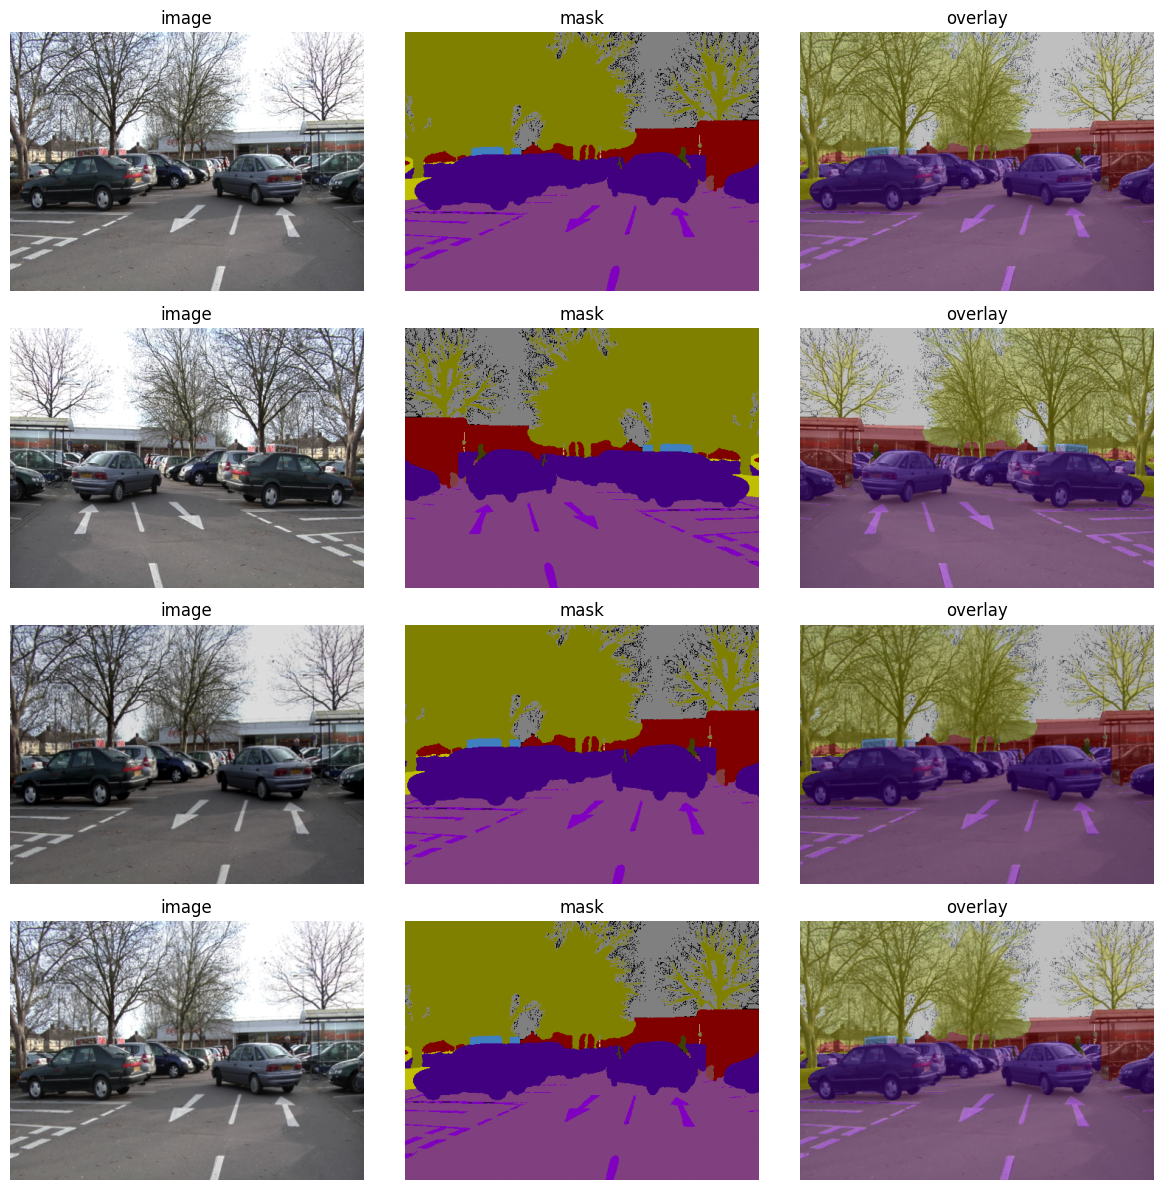

In [9]:
ds = loaders["train"].dataset   # augment=True for the train set

fig, axes = plt.subplots(4, 3, figsize=(12, 12))
for r in range(4):
    img, mask = ds[50]           # same sample, a different random augmentation each time
    rgb = denormalize(img)
    mask_rgb = mapper.index_to_rgb(mask.numpy()) / 255.0   # ignored pixels appear black
    overlay = 0.5 * rgb + 0.5 * mask_rgb
    for ax, im, title in zip(axes[r], [rgb, mask_rgb, overlay], ["image", "mask", "overlay"]):
        ax.imshow(im)
        ax.set_title(title)
        ax.axis("off")
plt.tight_layout()
plt.show()

In [10]:
imgs, masks = next(iter(loaders["train"]))

print("shapes:", tuple(imgs.shape), tuple(masks.shape), "| dtypes:", imgs.dtype, masks.dtype)
print("image mean per channel:", imgs.mean(dim=(0, 2, 3)))
print("image std per channel: ", imgs.std(dim=(0, 2, 3)))

values = masks.unique().tolist()
print("mask values:", values)
assert all(v < mapper.num_classes or v == 255 for v in values), "unexpected class index"
print("ignored pixels: %.2f %%" % (100 * (masks == 255).float().mean().item()))

shapes: (8, 3, 352, 480) (8, 352, 480) | dtypes: torch.float32 torch.int64
image mean per channel: tensor([-0.2303, -0.0715,  0.1476])
image std per channel:  tensor([1.3080, 1.3428, 1.3216])
mask values: [1, 2, 4, 5, 6, 7, 8, 9, 10, 11, 12, 14, 15, 16, 17, 18, 19, 20, 21, 22, 24, 26, 27, 29, 30, 255]
ignored pixels: 3.21 %
